In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pingouin as pg
import seaborn as sns

In [2]:
sequences = pd.read_csv('../data/interim/sequences_nf9_mutants.csv', index_col='id')

In [3]:
sequences = sequences[sequences['mutant'] != 'L'].copy()

In [4]:
sequences['id_original'] = (
    sequences.index.str.replace('_mut_[A-Z]$', '', regex=True)
    .str.replace('^nf9_', '', regex=True)
    .str.replace('_', '-')
)

In [5]:
sequences['mutant'] = sequences['mutant'].fillna('WT (L)')

In [6]:
sequences['status'] = 'Mutation'
sequences.loc[sequences['mutant'] == 'WT (L)', 'status'] = 'Wild type'

In [7]:
sequences['mutation_type'] = 'Other mutation'
sequences.loc[sequences['mutant'] == 'WT (L)', 'mutation_type'] = 'Wild type'
sequences.loc[sequences['mutant'].isin({'R', 'Q'}), 'mutation_type'] = 'Escape variant (R or Q)'

In [8]:
binding_scores = pd.read_csv('../data/processed/af3_af3_tcrmodel2_nf9_mutants_pae_aggregator_predictions.csv')

binding_scores['prediction'] = binding_scores[
    ['prediction_1', 'prediction_2', 'prediction_3', 'prediction_4', 'prediction_5']
].apply('median', axis=1)

binding_scores = binding_scores.merge(sequences, how='inner', left_on='name', right_index=True)

In [9]:
activations = binding_scores.pivot_table(index='id_original', columns='mutant', values='prediction', dropna=False)
activations = activations[['WT (L)', *[column for column in activations.columns if column != 'WT (L)']]]
activations = activations.sort_index(
    key=lambda index: [
        [
            'P1-15',
            'P1-1',
            '2-2',
            '5-3',
            '19-1',
            '20-2',
            '18-10',
            '10-11',
            '16-2',
            '10-4',
            '11-3',
            '17',
            '12-3',
        ].index(id_)
        for id_ in index
    ]
)

In [10]:
activations_norm = activations.div(activations.max(axis=1), axis=0)

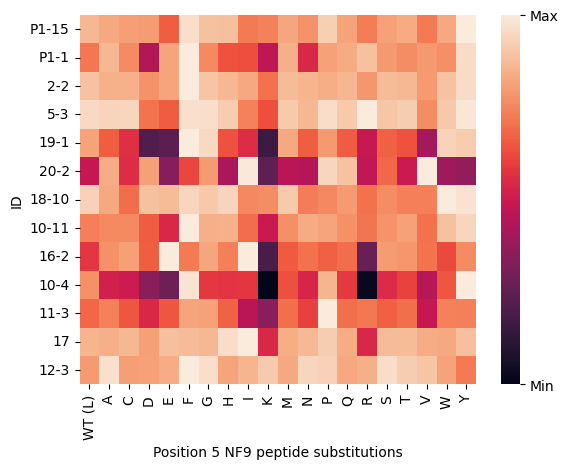

In [11]:
ax = sns.heatmap(activations_norm)

ax.set_xlabel('Position 5 NF9 peptide substitutions')
ax.set_ylabel('ID')

cbar = ax.collections[0].colorbar
vmin, vmax = ax.collections[0].get_clim()

cbar.set_ticks([vmin, vmax])
cbar.set_ticklabels(['Min', 'Max'])

plt.show()

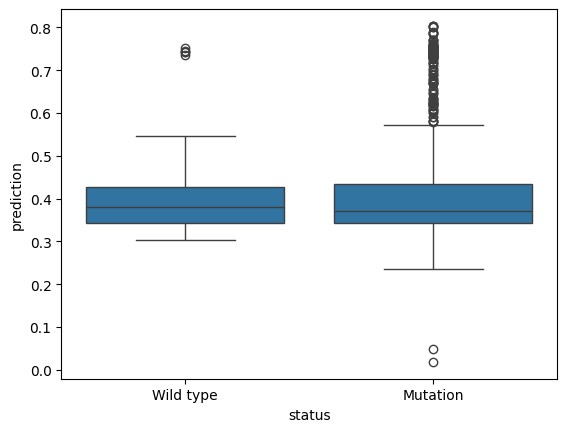

In [12]:
sns.boxplot(binding_scores, y='prediction', x='status')
plt.show()

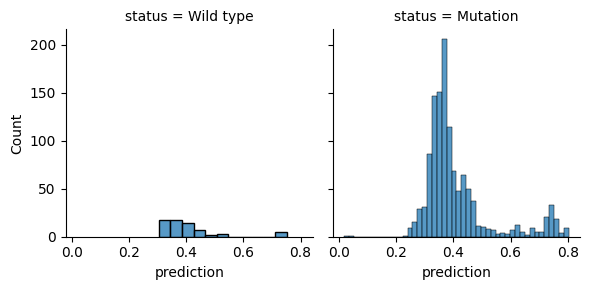

In [13]:
grid = sns.FacetGrid(binding_scores, col='status')
grid.map_dataframe(sns.histplot, x='prediction')
plt.show()

In [14]:
pg.mwu(
    binding_scores.loc[binding_scores['status'] == 'Wild type', 'prediction'],
    binding_scores.loc[binding_scores['status'] == 'Mutation', 'prediction'],
    alternative='greater',
)

,U-val,alternative,p-val,RBC,CLES
MWU,42550.0,greater,0.206794,0.060106,0.530053


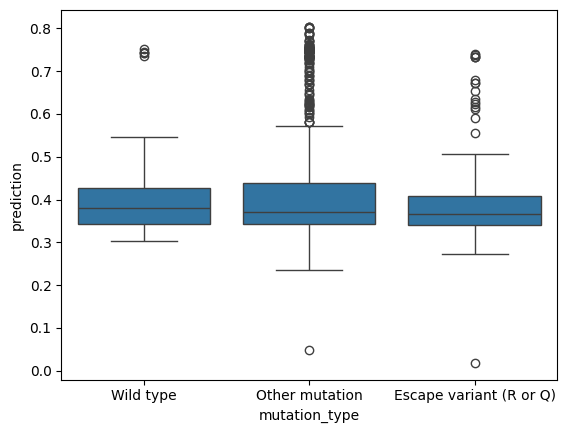

In [15]:
sns.boxplot(binding_scores, x='mutation_type', y='prediction')
plt.show()

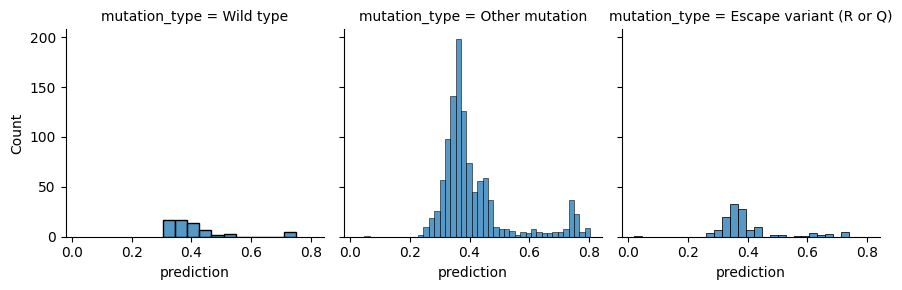

In [16]:
grid = sns.FacetGrid(binding_scores, col='mutation_type')
grid.map_dataframe(sns.histplot, x='prediction')
plt.show()

In [17]:
pg.kruskal(binding_scores, dv='prediction', between='mutation_type')

,Source,ddof1,H,p-unc
Kruskal,mutation_type,2,3.322676,0.189885


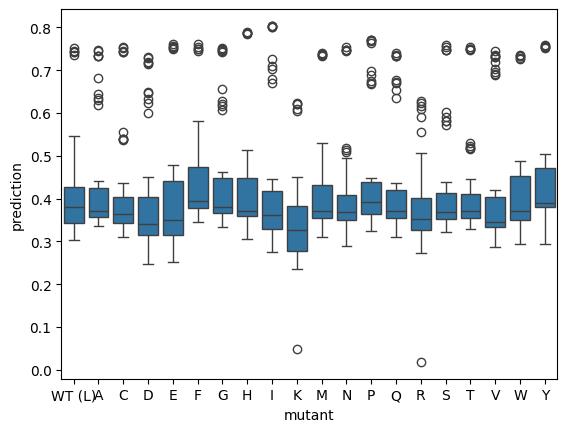

In [18]:
sns.boxplot(binding_scores, x='mutant', y='prediction')
plt.show()

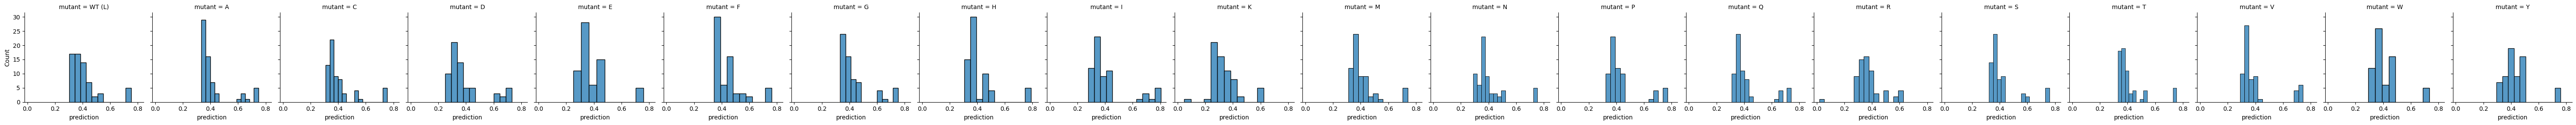

In [19]:
grid = sns.FacetGrid(binding_scores, col='mutant')
grid.map_dataframe(sns.histplot, x='prediction')
plt.show()

In [20]:
pg.anova(binding_scores, dv='prediction', between='mutant')

,Source,ddof1,ddof2,F,p-unc,np2
0,mutant,19,1280,2.661376,0.000135,0.038003


In [21]:
predictions = binding_scores.groupby('mutant')['prediction']
wild_type_prediction = predictions.get_group('WT (L)')

num_comparisons = len(predictions) - 1
significance_level = 0.05 / num_comparisons

results = []
for mutant, mutant_prediction in predictions:
    if mutant == 'WT (L)':
        continue

    result = pg.ttest(wild_type_prediction, mutant_prediction, alternative='greater')
    result['name'] = mutant

    results.append(result)

results = pd.concat(results)
results['significant'] = results['p-val'] < significance_level

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,name,significant
T-test,-0.397465,128,greater,0.654157,"[-0.04, inf]",0.069720,0.403,0.020664,A,False
T-test,0.441048,128,greater,0.329961,"[-0.02, inf]",0.077365,0.41,0.113883,C,False
T-test,1.157083,128,greater,0.124697,"[-0.01, inf]",0.202966,0.689,0.310694,D,False
T-test,1.323433,128,greater,0.094025,"[-0.01, inf]",0.232145,0.83,0.371298,E,False
T-test,-1.682584,128,greater,0.952553,"[-0.06, inf]",0.295145,0.741,0.000452,F,False
T-test,-0.974559,128,greater,0.834191,"[-0.05, inf]",0.170949,0.577,0.004471,G,False
T-test,0.092883,128,greater,0.463071,"[-0.03, inf]",0.016293,0.377,0.060276,H,False
T-test,-0.145693,128,greater,0.557804,"[-0.04, inf]",0.025556,0.379,0.036745,I,False
T-test,3.961761,128,greater,0.000061,"[0.04, inf]",0.694939,359.222,0.989158,K,True
T-test,0.046187,128,greater,0.481617,"[-0.03, inf]",0.008102,0.375,0.054920,M,False
